In [1]:
import pandas as pd
import geopandas as gpd

In [2]:
field="kaybobs"

In [3]:
fields_df=gpd.read_file(r"C:\Users\Keith.Johnson\OneDrive - Paramount Resource Ltd\00_Projects\Alberta_Well_App\AER_Order_System_SHP\Field_region.shp")
fields_df=fields_df.to_crs("epsg:4326")
wells_df=gpd.read_file(r"C:\Users\Keith.Johnson\OneDrive - Paramount Resource Ltd\00_Projects\Alberta_Well_App\ST37_BH.SHP")

c:\Users\Keith.Johnson\AppData\Local\miniconda3\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


In [4]:
selectedfield=fields_df[fields_df["ABBREVIATI"]==field.upper()]
selected_points = gpd.sjoin(wells_df, selectedfield, how="inner", predicate="within")
selected_points=selected_points[selected_points["Year"]>=2016].copy()
selected_points["LATITUDE"]=selected_points.geometry.y
selected_points["LONGITUDE"]=selected_points.geometry.x

<Axes: >

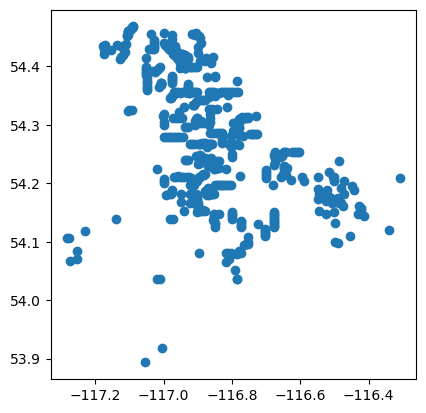

In [5]:
selected_points.plot()

In [ ]:
df=pd.DataFrame(selected_points)
newdf = df.drop(["geometry","Id","index_right","ABBREVIATI","LAYER"],axis=1)
newdf = newdf.rename(columns={"Final_Tota":"Final_Total_Depth","Licence_St":"Licence_Status"})
newdf = newdf.reset_index(drop=True)
welljson=newdf.to_json(orient='records')

In [7]:
with open("function.js", "w", encoding="utf-8") as f:
    f.write(f"function {field}wells(){{\n")
    f.write(f"   var wellData={welljson};\n")
    f.write("   return wellData;\n")
    f.write("}\n")
    